# Baseline results

In [1]:
import os
import subprocess
from pathlib import Path

# configs/base.yaml is resolved relative to the repo root
if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd

from f1_strategy_engine.config import get_config
from f1_strategy_engine.evaluation.report import plot_residuals, train_and_score

# plot_residuals builds its Figure without pyplot, and this magic is
# what registers Jupyter's PNG display for bare Figure objects.
%matplotlib inline

In [2]:
T = pd.Timestamp.now(tz="UTC")
PIT_MODE = get_config().pit_mode

commit = subprocess.run(
    ["git", "describe", "--always", "--dirty"], capture_output=True, text=True
).stdout.strip()
print(f"t = {T:%Y-%m-%d %H:%M} UTC | pit_mode = {PIT_MODE} | commit = {commit}")

run = train_and_score(T, PIT_MODE)

t = 2026-10-14 10:42 UTC | pit_mode = ROWS_ONLY | commit = eeb0a18


## Split

In [3]:
pd.DataFrame(
    {
        split: {
            "rounds": f"{df['round'].min()}-{df['round'].max()}",
            "circuits": df["circuit"].nunique(),
            "laps": len(df),
        }
        for split, df in [("train", run.train), ("test", run.test)]
    }
).T

,rounds,circuits,laps
train,1-18,18,20280
test,19-24,6,6324


## B1 degradation slopes


In [4]:
run.models["B1"].slopes_.rename("s_per_lap").round(3)

SOFT      0.058
MEDIUM   -0.008
HARD      0.004
Name: s_per_lap, dtype: float64

## Results table

In [5]:
run.results.round(3)

n_scored   rmse    mae
model compound                        
B0    ALL           4356  1.025  0.750
      MEDIUM        1677  1.075  0.818
      HARD          2608  0.980  0.699
      SOFT            71  1.379  1.002
B1    ALL           4356  0.998  0.755
      MEDIUM        1677  1.083  0.847
      HARD          2608  0.937  0.695
      SOFT            71  1.056  0.769

## Residuals

Residual = actual − predicted: positive means the lap was slower than the model expected. The
y-axis is clipped to the 1st–99th percentile; the boxplot fliers show the tails.

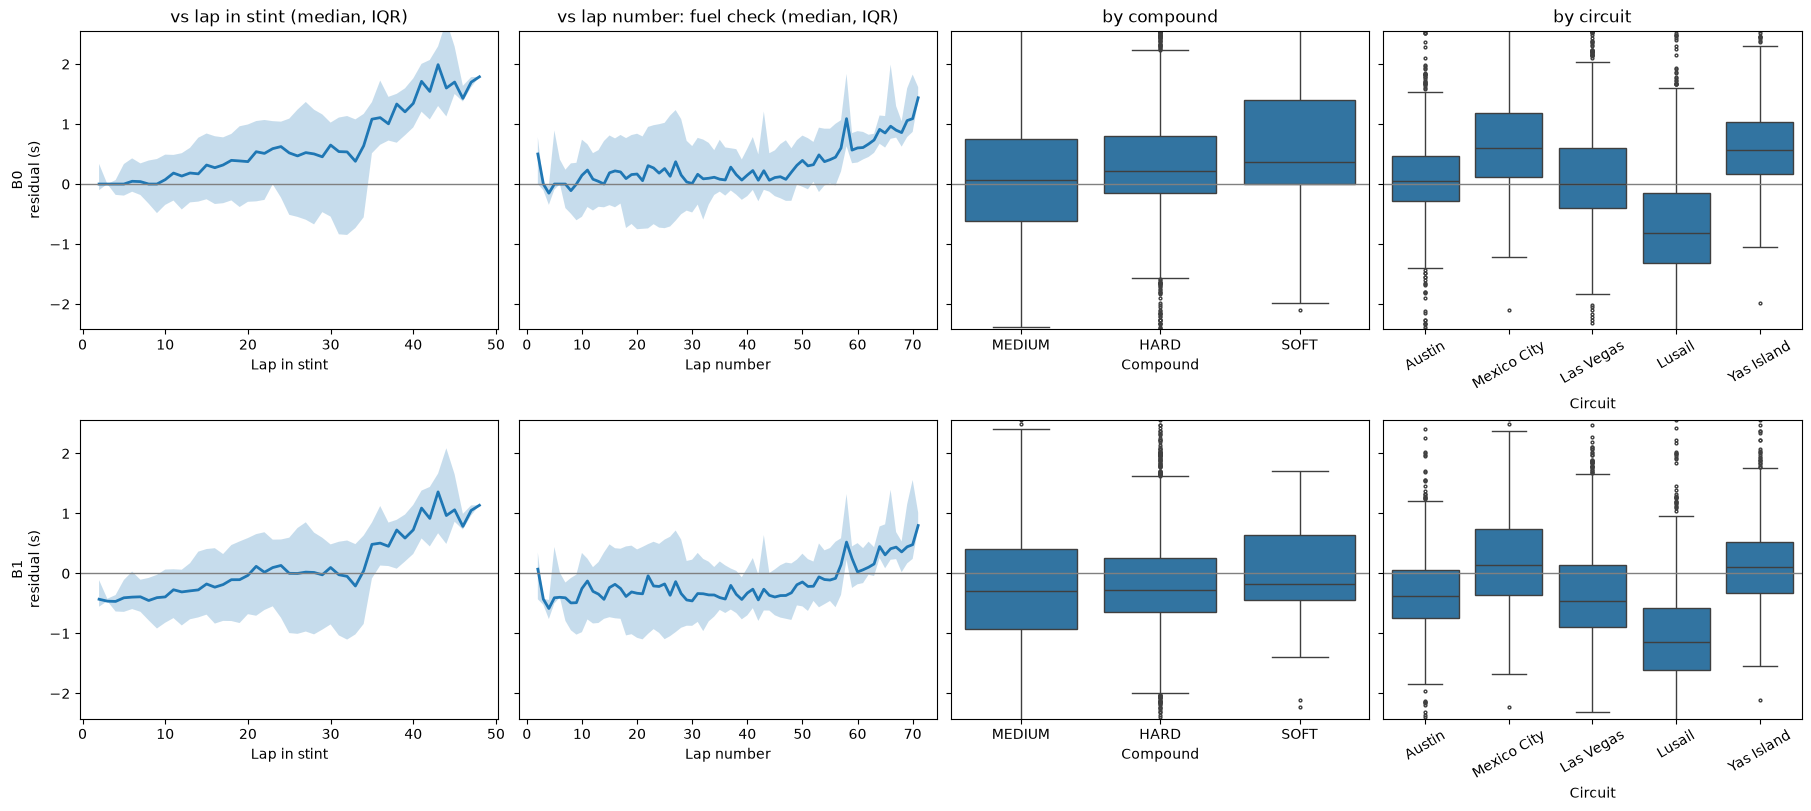

In [6]:
plot_residuals(run.residuals)